# Kiểm chứng công thức S tại nhiều ngày đánh giá và với nhiều số mũ

`kiem_chung_cong_thuc_S.ipynb` chỉ dùng ba ngày đánh giá. Ba ngày này dùng chung phần lớn tập lỗ hổng và có cửa sổ theo dõi chồng lên nhau, nên chưa phải ba lần lặp độc lập. Notebook này lặp lại **đúng thiết kế đó** để trả lời ba câu hỏi:

1. Kết quả có ổn định qua **11 ngày cuối quý** từ 31/03/2023 đến 30/09/2025 không?
2. Kết quả có giữ nguyên ở **ba ngày có cửa sổ theo dõi không chồng nhau** (31/03/2023, 31/03/2024, 31/03/2025) không?
3. Kết luận có phụ thuộc vào **số mũ 0,3** không? Thử các số mũ 0,1; 0,2; 0,3; 0,5; 0,7 và 1,0.

Thiết kế: tại ngày T, xét lỗ hổng đã công bố, có CVSS 3.x và chưa có trong KEV; EPSS lấy đúng ngày T (lỗ hổng không có điểm coi bằng 0); nhãn là vào KEV trong 365 ngày sau T. Danh mục KEV được cắt về 08/10/2026, đúng phiên bản các notebook khác đã dùng. Ngày cuối cùng là 30/09/2025 để cửa sổ 365 ngày kết thúc trước 08/10/2026.

## 1. Cấu hình và hàm dùng chung

In [1]:
import os, io, json, gzip, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

START_YEAR, END_YEAR = 2002, 2025
KEV_DEN_NGAY = "2026-10-08"
NGAY_DANH_GIA = [str(d.date()) for d in pd.date_range("2023-03-31", "2025-09-30", freq="QE")]
NGAY_DOC_LAP = ["2023-03-31", "2024-03-31", "2025-03-31"]       # cua so theo doi khong chong nhau
NGAY_CU = ["2023-12-31", "2024-12-31", "2025-06-30"]            # ba ngay cua kiem_chung_cong_thuc_S.ipynb
THEO_DOI, SO_MU, NGUONG_CSA = 365, 0.3, 8.0
LUOI_SO_MU = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
KHOI_LUONG = [0.01, 0.05, 0.10, 0.25]
DATA_DIR, OUT_DIR = "du_lieu_nvd", "ket_qua_nhieu_ngay"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

NVD_FEED = "https://nvd.nist.gov/feeds/json/cve/2.0/nvdcve-2.0-{y}.json.gz"
KEV_URL = "https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json"
EPSS_URL = "https://epss.empiricalsecurity.com/epss_scores-{d}.csv.gz"
UA = {"User-Agent": "Nhom14-course-research"}
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})

def tai(url, path):
    if os.path.exists(path):
        return open(path, "rb").read()
    data = urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=300).read()
    open(path, "wb").write(data)
    return data

def so(x): return f"{int(round(x)):,}".replace(",", ".")
def pct(v, k=2): return f"{v:.{k}f}".replace(".", ",")
def ty_le(a, b, k=2):
    if b == 0: return ""
    a_txt = so(a) if float(a).is_integer() else pct(a, 1)
    return f"{a_txt} / {so(b)} = {pct(100 * a / b, k)}%"

def so_bat_duoc(diem, y, k):
    """So lo hong vao KEV nam trong k lo hong diem cao nhat, lo hong bang diem o ranh gioi tinh theo gia tri ky vong."""
    k = int(k)
    if k <= 0: return 0.0
    if k >= len(diem): return float(y.sum())
    t = np.partition(diem, len(diem) - k)[len(diem) - k]
    tren, bang = diem > t, diem == t
    return float(y[tren].sum() + (k - tren.sum()) * y[bang].sum() / bang.sum())

def tai_epss(T):
    """EPSS dung ngay T; neu ngay do thieu tep thi lui toi da 4 ngay. Tra ve (bang diem, ngay thuc dung, phien ban mo hinh)."""
    for lui in range(5):
        d = str((pd.Timestamp(T) - pd.Timedelta(days=lui)).date())
        try:
            raw = gzip.decompress(tai(EPSS_URL.format(d=d), os.path.join(DATA_DIR, f"epss_{d}.csv.gz"))).decode()
        except Exception:
            continue
        ep = pd.read_csv(io.StringIO(raw), comment="#")
        return dict(zip(ep["cve"].str.upper(), ep["epss"])), d, raw.splitlines()[0].split(",")[0].replace("#model_version:", "")
    raise FileNotFoundError(f"không có tệp EPSS quanh ngày {T}")

BANG, SO_LIEU = {}, {}

## 2. Tải KEV và NVD

In [2]:
kev = pd.DataFrame(json.loads(tai(KEV_URL, os.path.join(DATA_DIR, "kev.json")))["vulnerabilities"])
kev["cveID"] = kev["cveID"].str.upper(); kev["ngay_kev"] = pd.to_datetime(kev["dateAdded"])
kev = kev[kev["ngay_kev"] <= KEV_DEN_NGAY]

def chon(ds):
    if not ds: return None
    for m in ds:
        if m.get("type") == "Primary": return m
    return ds[0]

rows = []
for y in range(START_YEAR, END_YEAR + 1):
    js = json.loads(gzip.decompress(tai(NVD_FEED.format(y=y), os.path.join(DATA_DIR, f"nvdcve-2.0-{y}.json.gz"))))
    for it in js["vulnerabilities"]:
        c = it["cve"]
        if c.get("vulnStatus") == "Rejected": continue
        met = c.get("metrics", {})
        v3 = chon(met.get("cvssMetricV31")) or chon(met.get("cvssMetricV30"))
        rows.append({"cve": c["id"].upper(), "ngay_cong_bo": c["published"][:10],
                     "cvss": v3["cvssData"]["baseScore"] if v3 else np.nan})
nvd = pd.DataFrame(rows).drop_duplicates("cve")
nvd = nvd[nvd["cvss"].notna()].copy()
nvd["ngay_cong_bo"] = pd.to_datetime(nvd["ngay_cong_bo"])
nvd["ngay_kev"] = nvd["cve"].map(dict(zip(kev["cveID"], kev["ngay_kev"])))
print(f"KEV đến {KEV_DEN_NGAY}: {so(len(kev))} lỗ hổng; NVD: {so(len(nvd))} lỗ hổng có CVSS 3.x")

KEV đến 2026-10-08: 1.739 lỗ hổng; NVD: 240.409 lỗ hổng có CVSS 3.x


## 3. Dựng dữ liệu tại 11 ngày đánh giá

Với mỗi ngày, tính số lỗ hổng bắt được khi vá 1%, 5%, 10%, 25% và khi vá bằng số lượng của quy tắc CSA, theo CVSS, EPSS và công thức S. Lỗ hổng bằng điểm ở ranh giới được tính theo giá trị kỳ vọng.

In [3]:
DL, rows = {}, []
for T in NGAY_DANH_GIA:
    Tt = pd.Timestamp(T); H = Tt + pd.Timedelta(days=THEO_DOI)
    emap, d_epss, phien_ban = tai_epss(T)
    c = nvd[(nvd["ngay_cong_bo"] <= Tt) & ~(nvd["ngay_kev"] <= Tt)].copy()
    c["epss"] = c["cve"].map(emap).fillna(0.0)
    c["y"] = ((c["ngay_kev"] > Tt) & (c["ngay_kev"] <= H)).astype(int)
    DL[T] = (c["cvss"].values, c["epss"].values, c["y"].values)
    rows.append([T, d_epss, phien_ban, so(len(c)), so(c["y"].sum())])
    SO_LIEU.setdefault("du_lieu", {})[T] = dict(N=len(c), P=int(c["y"].sum()), ngay_epss=d_epss, mo_hinh=phien_ban)
b0 = pd.DataFrame(rows, columns=["Ngày đánh giá", "Tệp EPSS dùng", "Mô hình EPSS", "Lỗ hổng chưa có trong KEV",
                                 "Vào KEV trong 12 tháng sau"])
BANG["C0 Du lieu"] = b0
display(b0)

,Ngày đánh giá,Tệp EPSS dùng,Mô hình EPSS,Lỗ hổng chưa có trong KEV,Vào KEV trong 12 tháng sau
0,2023-03-31,2023-03-31,v2023.03.01,125.623,56
1,2023-06-30,2023-06-30,v2023.03.01,132.695,39
2,2023-09-30,2023-09-30,v2023.03.01,139.582,60
3,2023-12-31,2023-12-31,v2023.03.01,147.313,61
4,2024-03-31,2024-03-31,v2023.03.01,155.951,68
5,2024-06-30,2024-06-30,v2023.03.01,167.581,78
6,2024-09-30,2024-09-30,v2023.03.01,175.967,76
7,2024-12-31,2024-12-31,v2023.03.01,186.756,80
8,2025-03-31,2025-03-31,v2025.03.14,198.373,77
9,2025-06-30,2025-06-30,v2025.03.14,209.623,91


## 4. Bảng C1. Ba cách xếp hạng tại 11 ngày đánh giá

Các cột ghi tỷ lệ lỗ hổng vào KEV trong 12 tháng sau được bắt khi vá cùng số lượng. Cột *Ngưỡng S từ 70* tính hiệu suất của nhóm vá khẩn cấp đề xuất: tỷ lệ bắt được chia cho tỷ lệ khối lượng vá, tức gấp bao nhiêu lần chọn ngẫu nhiên.

In [4]:
def ket_qua(T, so_mu=SO_MU):
    cv, ep, y = DL[T]; S = cv * np.power(ep, so_mu) * 10; N, P = len(y), int(y.sum())
    kq = {}
    for f in KHOI_LUONG + ["csa"]:
        k = int((cv >= NGUONG_CSA).sum()) if f == "csa" else int(f * N)
        kq[f] = {"CVSS": so_bat_duoc(cv, y, k), "EPSS": so_bat_duoc(ep, y, k), "S": so_bat_duoc(S, y, k), "k": k}
    return kq, S, N, P

rows = []
for T in NGAY_DANH_GIA:
    kq, S, N, P = ket_qua(T)
    cv, ep, y = DL[T]; n70 = int((S >= 70).sum()); k70 = int(y[S >= 70].sum())
    hs70 = (k70 / P) / (n70 / N)
    hscsa = (kq["csa"]["CVSS"] / P) / (kq["csa"]["k"] / N)
    rows.append([T, so(P), *[f"{pct(100 * kq[f][m] / P, 1)}%" for f in [0.01, 0.05] for m in ["CVSS", "EPSS", "S"]],
                 f"{pct(hs70, 1)} lần", f"{pct(hscsa, 1)} lần"])
    SO_LIEU.setdefault("ket_qua", {})[T] = {str(f): v for f, v in kq.items()} | {"n70": n70, "k70": k70}
b1 = pd.DataFrame(rows, columns=["Ngày đánh giá", "Vào KEV trong 12 tháng",
                                 "Vá 1%: CVSS", "Vá 1%: EPSS", "Vá 1%: S", "Vá 5%: CVSS", "Vá 5%: EPSS", "Vá 5%: S",
                                 "Ngưỡng S từ 70: gấp ngẫu nhiên", "Quy tắc CSA: gấp ngẫu nhiên"])
BANG["C1 Theo ngay"] = b1
display(b1)

,Ngày đánh giá,Vào KEV trong 12 tháng,Vá 1%: CVSS,Vá 1%: EPSS,Vá 1%: S,Vá 5%: CVSS,Vá 5%: EPSS,Vá 5%: S,Ngưỡng S từ 70: gấp ngẫu nhiên,Quy tắc CSA: gấp ngẫu nhiên
0,2023-03-31,56,"1,4%","26,8%","25,0%","11,7%","33,9%","33,9%","21,4 lần","1,7 lần"
1,2023-06-30,39,"4,3%","38,5%","38,5%","16,7%","51,3%","51,3%","34,2 lần","2,0 lần"
2,2023-09-30,60,"4,6%","23,3%","26,7%","13,7%","50,0%","48,3%","24,6 lần","2,0 lần"
3,2023-12-31,61,"3,3%","23,0%","23,0%","14,6%","49,2%","49,2%","22,6 lần","2,1 lần"
4,2024-03-31,68,"4,5%","23,5%","20,6%","15,6%","39,7%","39,7%","21,6 lần","2,0 lần"
5,2024-06-30,78,"3,0%","16,7%","17,9%","15,4%","33,3%","37,2%","15,9 lần","2,1 lần"
6,2024-09-30,76,"2,8%","19,7%","18,4%","13,1%","32,9%","30,3%","20,4 lần","2,0 lần"
7,2024-12-31,80,"2,5%","22,5%","22,5%","12,1%","35,0%","32,5%","25,5 lần","2,1 lần"
8,2025-03-31,77,"2,7%","33,8%","31,2%","13,3%","54,5%","55,8%","31,5 lần","2,3 lần"
9,2025-06-30,91,"5,3%","33,0%","27,5%","12,4%","56,0%","54,9%","27,9 lần","2,1 lần"


## 5. Bảng C2. Tổng hợp: toàn bộ 11 ngày, và riêng ba ngày có cửa sổ không chồng nhau

Gộp số lỗ hổng bắt được và tổng số lỗ hổng vào KEV của các ngày trong nhóm. Cột cuối đếm số ngày công thức S bắt được ít nhất bằng CVSS (hoặc EPSS).

In [5]:
rows = []
for ten_nhom, nhom in [("11 ngày cuối quý", NGAY_DANH_GIA), ("3 ngày cửa sổ không chồng nhau", NGAY_DOC_LAP)]:
    for f, ten_f in [(0.01, "Vá 1%"), (0.05, "Vá 5%"), (0.10, "Vá 10%"), (0.25, "Vá 25%"), ("csa", "Vá bằng số lượng quy tắc CSA")]:
        h = {m: sum(SO_LIEU["ket_qua"][T][str(f)][m] for T in nhom) for m in ["CVSS", "EPSS", "S"]}
        P = sum(SO_LIEU["du_lieu"][T]["P"] for T in nhom)
        hon_cvss = sum(SO_LIEU["ket_qua"][T][str(f)]["S"] >= SO_LIEU["ket_qua"][T][str(f)]["CVSS"] for T in nhom)
        hon_epss = sum(SO_LIEU["ket_qua"][T][str(f)]["S"] >= SO_LIEU["ket_qua"][T][str(f)]["EPSS"] for T in nhom)
        rows.append([ten_nhom, ten_f, ty_le(h["CVSS"], P, 1), ty_le(h["EPSS"], P, 1), ty_le(h["S"], P, 1),
                     f"{hon_cvss}/{len(nhom)}", f"{hon_epss}/{len(nhom)}"])
b2 = pd.DataFrame(rows, columns=["Nhóm ngày", "Khối lượng vá", "Theo CVSS", "Theo EPSS", "Theo công thức S",
                                 "Số ngày S không kém CVSS", "Số ngày S không kém EPSS"])
BANG["C2 Tong hop"] = b2
display(b2)

,Nhóm ngày,Khối lượng vá,Theo CVSS,Theo EPSS,Theo công thức S,Số ngày S không kém CVSS,Số ngày S không kém EPSS
0,11 ngày cuối quý,Vá 1%,"28,7 / 776 = 3,7%","201 / 776 = 25,9%","193 / 776 = 24,9%",11/11,6/11
1,11 ngày cuối quý,Vá 5%,"107,0 / 776 = 13,8%","343 / 776 = 44,2%","341 / 776 = 43,9%",11/11,7/11
2,11 ngày cuối quý,Vá 10%,"204,8 / 776 = 26,4%","411 / 776 = 53,0%","415 / 776 = 53,5%",11/11,9/11
3,11 ngày cuối quý,Vá 25%,"420,2 / 776 = 54,1%","517,5 / 776 = 66,7%","520 / 776 = 67,0%",11/11,6/11
4,11 ngày cuối quý,Vá bằng số lượng quy tắc CSA,"460 / 776 = 59,3%","534 / 776 = 68,8%","549,7 / 776 = 70,8%",11/11,9/11
5,3 ngày cửa sổ không chồng nhau,Vá 1%,"6,0 / 201 = 3,0%","57 / 201 = 28,4%","52 / 201 = 25,9%",3/3,0/3
6,3 ngày cửa sổ không chồng nhau,Vá 5%,"27,4 / 201 = 13,6%","88 / 201 = 43,8%","89 / 201 = 44,3%",3/3,3/3
7,3 ngày cửa sổ không chồng nhau,Vá 10%,"54,1 / 201 = 26,9%","107 / 201 = 53,2%","111 / 201 = 55,2%",3/3,3/3
8,3 ngày cửa sổ không chồng nhau,Vá 25%,"106,4 / 201 = 52,9%","136 / 201 = 67,7%","137 / 201 = 68,2%",3/3,2/3
9,3 ngày cửa sổ không chồng nhau,Vá bằng số lượng quy tắc CSA,"117 / 201 = 58,2%","139 / 201 = 69,2%","141 / 201 = 70,1%",3/3,2/3


## 6. Bảng C3. Quét số mũ

Gộp 11 ngày, tính tỷ lệ lỗ hổng vào KEV bắt được ở mỗi khối lượng vá, với từng số mũ của EPSS trong công thức S. Số mũ càng nhỏ thì CVSS càng có trọng lượng; số mũ 1,0 tương đương nhân thẳng CVSS với EPSS.

In [6]:
rows = []
P = sum(SO_LIEU["du_lieu"][T]["P"] for T in NGAY_DANH_GIA)
SO_LIEU["quet_so_mu"] = {}
for a in LUOI_SO_MU:
    h = {f: 0.0 for f in KHOI_LUONG}
    for T in NGAY_DANH_GIA:
        kq, _, _, _ = ket_qua(T, a)
        for f in KHOI_LUONG: h[f] += kq[f]["S"]
    rows.append([pct(a, 1), *[f"{pct(100 * h[f] / P, 1)}%" for f in KHOI_LUONG], f"{pct(100 * np.mean([h[f] for f in KHOI_LUONG]) / P, 1)}%"])
    SO_LIEU["quet_so_mu"][str(a)] = {str(f): h[f] for f in KHOI_LUONG}
b3 = pd.DataFrame(rows, columns=["Số mũ", "Vá 1%", "Vá 5%", "Vá 10%", "Vá 25%", "Trung bình bốn khối lượng"])
BANG["C3 Quet so mu"] = b3
display(b3)

,Số mũ,Vá 1%,Vá 5%,Vá 10%,Vá 25%,Trung bình bốn khối lượng
0,"0,1","22,2%","41,1%","50,6%","69,3%","45,8%"
1,"0,2","24,7%","43,8%","52,2%","67,5%","47,1%"
2,"0,3","24,9%","43,9%","53,5%","67,0%","47,3%"
3,"0,5","25,9%","44,3%","54,1%","66,9%","47,8%"
4,"0,7","25,8%","44,3%","54,3%","66,6%","47,7%"
5,"1,0","25,8%","44,2%","54,0%","66,9%","47,7%"


## 7. Kiểm tra tái lập với `kiem_chung_cong_thuc_S.ipynb`

Ba ngày cũ có trong 11 ngày mới. Nếu dữ liệu NVD không thay đổi giữa hai lần tải, số lỗ hổng và số lỗ hổng vào KEV phải trùng với kết quả đã lưu.

In [7]:
cu = json.load(open("ket_qua_S/so_lieu_S.json", encoding="utf-8"))
rows = []
for T in NGAY_CU:
    moi = SO_LIEU["du_lieu"][T]; ss = cu["so_sanh"][f"{T} Vá 1% số lỗ hổng"]
    rows.append([T, so(cu[T]["chua"]), so(moi["N"]), so(cu[T]["P"]), so(moi["P"]),
                 pct(ss["S"], 1), pct(SO_LIEU["ket_qua"][T]["0.01"]["S"], 1)])
b4 = pd.DataFrame(rows, columns=["Ngày", "Lỗ hổng (lần trước)", "Lỗ hổng (lần này)", "Vào KEV (lần trước)",
                                 "Vào KEV (lần này)", "S bắt được khi vá 1% (lần trước)", "S bắt được khi vá 1% (lần này)"])
BANG["C4 Tai lap"] = b4
display(b4)

,Ngày,Lỗ hổng (lần trước),Lỗ hổng (lần này),Vào KEV (lần trước),Vào KEV (lần này),S bắt được khi vá 1% (lần trước),S bắt được khi vá 1% (lần này)
0,2023-12-31,147.313,147.313,61,61,"14,0","14,0"
1,2024-12-31,186.756,186.756,80,80,"18,0","18,0"
2,2025-06-30,209.623,209.623,91,91,"25,0","25,0"


## 8. Hình 1. Tỷ lệ bắt được khi vá 5% số lỗ hổng, tại 11 ngày đánh giá

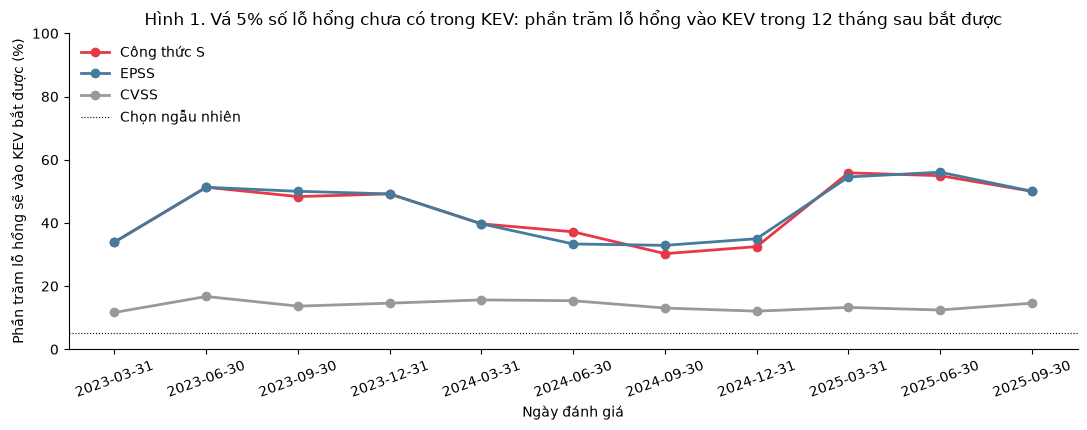

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.4))
for m, ten, mau in [("S", "Công thức S", "#e63946"), ("EPSS", "EPSS", "#457b9d"), ("CVSS", "CVSS", "#999999")]:
    v = [100 * SO_LIEU["ket_qua"][T]["0.05"][m] / SO_LIEU["du_lieu"][T]["P"] for T in NGAY_DANH_GIA]
    ax.plot(NGAY_DANH_GIA, v, "o-", color=mau, lw=2, label=ten)
ax.axhline(5, color="black", lw=0.8, ls=":", label="Chọn ngẫu nhiên")
ax.set_ylim(0, 100); ax.set_ylabel("Phần trăm lỗ hổng sẽ vào KEV bắt được (%)"); ax.set_xlabel("Ngày đánh giá")
ax.tick_params(axis="x", labelrotation=20); ax.legend(frameon=False, loc="upper left")
ax.set_title("Hình 1. Vá 5% số lỗ hổng chưa có trong KEV: phần trăm lỗ hổng vào KEV trong 12 tháng sau bắt được")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh1_va_5_phan_tram.png"), dpi=170); plt.show()

## 9. Lưu kết quả

In [9]:
with pd.ExcelWriter(os.path.join(OUT_DIR, "bang_nhieu_ngay.xlsx")) as w:
    for ten, b in BANG.items():
        b.to_excel(w, sheet_name=ten[:31], index=False)
for ten, b in BANG.items():
    b.to_csv(os.path.join(OUT_DIR, ten.replace(" ", "_") + ".csv"), index=False, encoding="utf-8-sig")
json.dump(SO_LIEU, open(os.path.join(OUT_DIR, "so_lieu_nhieu_ngay.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2,
          default=lambda o: int(o) if isinstance(o, np.integer) else float(o))
print("Đã lưu:", ", ".join(sorted(os.listdir(OUT_DIR))))

Đã lưu: C0_Du_lieu.csv, C1_Theo_ngay.csv, C2_Tong_hop.csv, C3_Quet_so_mu.csv, C4_Tai_lap.csv, bang_nhieu_ngay.xlsx, hinh1_va_5_phan_tram.png, so_lieu_nhieu_ngay.json
